# Demo: nhập truy vấn → top-k ảnh + quan hệ/đường đi giải thích

Sản phẩm nộp theo mục 8 của đề: *"Notebook hoặc giao diện nhỏ: nhập truy vấn, trả về top-k kết quả và hiển thị quan hệ/đường đi giải thích"*.

Dữ liệu: **MMKG Ẩm thực Việt Nam** tự xây (`mmkg/`, 148 thực thể, 750 triple, 316 ảnh). Cơ chế xếp hạng giữ đúng notebook `mmkg/Project3_MMKG_VN.ipynb` (mục 5, 9):

$$s(q,i)=\alpha\,z(\cos(q,i)) + (1-\alpha)\,z\Big(\sum_d P(d\mid q)\,\big[\lambda\,p_{GNN}(d\mid i)+(1-\lambda)\,p_{kNN}(d\mid i)\big]\Big)$$

**Giải thích lấy từ chính các số hạng của điểm đồ thị** (không sinh sau khi đã có kết quả):
1. món trung gian $d^*=\arg\max_d P(d\mid q)\,p(d\mid i)$ và tỉ lệ điểm đồ thị nó chiếm;
2. đường đi KG (1 hoặc 2 bước) từ thực thể nhắc trong truy vấn tới $d^*$ — chính là các ràng buộc tạo ra $P(d^*\mid q)$;
3. ảnh train gần nhất có cạnh `mô_tả` → $d^*$ — bằng chứng cho $p_{kNN}(d^*\mid i)$.

Ô **fidelity** xoá đúng các cạnh đó rồi chấm lại, so với xoá cùng số cạnh ngẫu nhiên.

Mặc định dùng CLIP đa ngữ `xlm-roberta-base-ViT-B-32` để chạy được trên CPU (~1 phút lần đầu, gồm tải mô hình). Đặt `P3_DEMO_MODEL=mclip_h14` nếu có GPU để dùng mô hình chính của báo cáo. Giao diện web tương đương: `python demo/app.py`.

In [1]:
# Colab / Kaggle: bỏ comment để cài thư viện (repo đã được clone sẵn cùng thư mục mmkg/)
# !pip -q install open_clip_torch==3.2.0 networkx ipywidgets
import os, sys
HERE = os.path.abspath("demo") if os.path.exists("demo/mmkg_engine.py") else os.path.abspath(".")
sys.path.insert(0, HERE)
from mmkg_engine import MMKGSearch
from viz import draw_explanation, result_html
import matplotlib.pyplot as plt
from IPython.display import display, HTML

## 1. Dựng KG, trích đặc trưng CLIP, huấn luyện R-SAGE, chọn tham số trên val

In [2]:
ENG = MMKGSearch(seed=0)   # split seed 0 lấy từ results/mmkg/splits.json; đặc trưng được cache ở demo/cache/

KG: 148 thực thể, 434 triple tri thức, 316 ảnh


Split seed 0 {'train': 145, 'val': 70, 'test': 101, 'all': 316}


Đặc trưng CLIP lấy từ cache: /home/user/du-lieu-do-thi/demo/cache/feats_mclip_b32.npz


GNN (R-SAGE) huấn luyện xong 7s; độ chính xác ảnh→món trên val 0.514


Sẵn sàng sau 7s | mô hình xlm-roberta-base-ViT-B-32 | tham số chọn trên val: {'alpha': 0.1, 'lam': 0.75, 'eta': 0.75, 'T': 0.03, 'w2': 0.5} (val MRR 0.735)


## 2. Gọi bằng hàm: `search()` + in giải thích

In [3]:
R = ENG.search("bánh mặn của Huế, có tôm", k=5, gallery="test")
ENG.print_result(R)

Nạp CLIP xlm-roberta-base-ViT-B-32/laion5b_s13b_b90k trên cpu …


Truy vấn: 'bánh mặn của Huế, có tôm'   (gallery: test, 101 ảnh)
Thực thể nhận ra trong KG: ['bánh mặn [loại món]', 'Huế [tỉnh]', 'tôm [nguyên liệu]']
P(món | truy vấn): Bánh bèo 0.55, Bánh bột lọc 0.45, Bánh khọt 0.00

#1 img_banh_bot_loc_10  [Bánh bột lọc]  điểm +5.05 = CLIP +0.04 + đồ thị +5.01
   qua món «Bánh bột lọc» ✓ (100% điểm đồ thị)
    Bánh bột lọc —thuộc_loại→ bánh mặn
    Bánh bột lọc —xuất_xứ→ Huế
    Bánh bột lọc —có_nguyên_liệu→ tôm
    ảnh bằng chứng —mô_tả→ Bánh bột lọc : img_banh_bot_loc_03, img_banh_bot_loc_07, img_banh_bot_loc_08

#2 img_banh_bot_loc_06  [Bánh bột lọc]  điểm +3.91 = CLIP -0.18 + đồ thị +4.09
   qua món «Bánh bột lọc» ✓ (100% điểm đồ thị)
    Bánh bột lọc —thuộc_loại→ bánh mặn
    Bánh bột lọc —xuất_xứ→ Huế
    Bánh bột lọc —có_nguyên_liệu→ tôm
    ảnh bằng chứng —mô_tả→ Bánh bột lọc : img_banh_bot_loc_07, img_banh_bot_loc_08, img_banh_bot_loc_03

#3 img_bun_oc_04  [Bún ốc]  điểm +3.66 = CLIP +0.11 + đồ thị +3.56
   qua món «Bánh bột lọc» ✗ (96% điể

Đồ thị con giải thích của kết quả #1: truy vấn → thực thể khớp ← món $d^*$ ← ảnh kết quả (dự đoán ảnh→món) và ảnh bằng chứng (cạnh `mô_tả`).

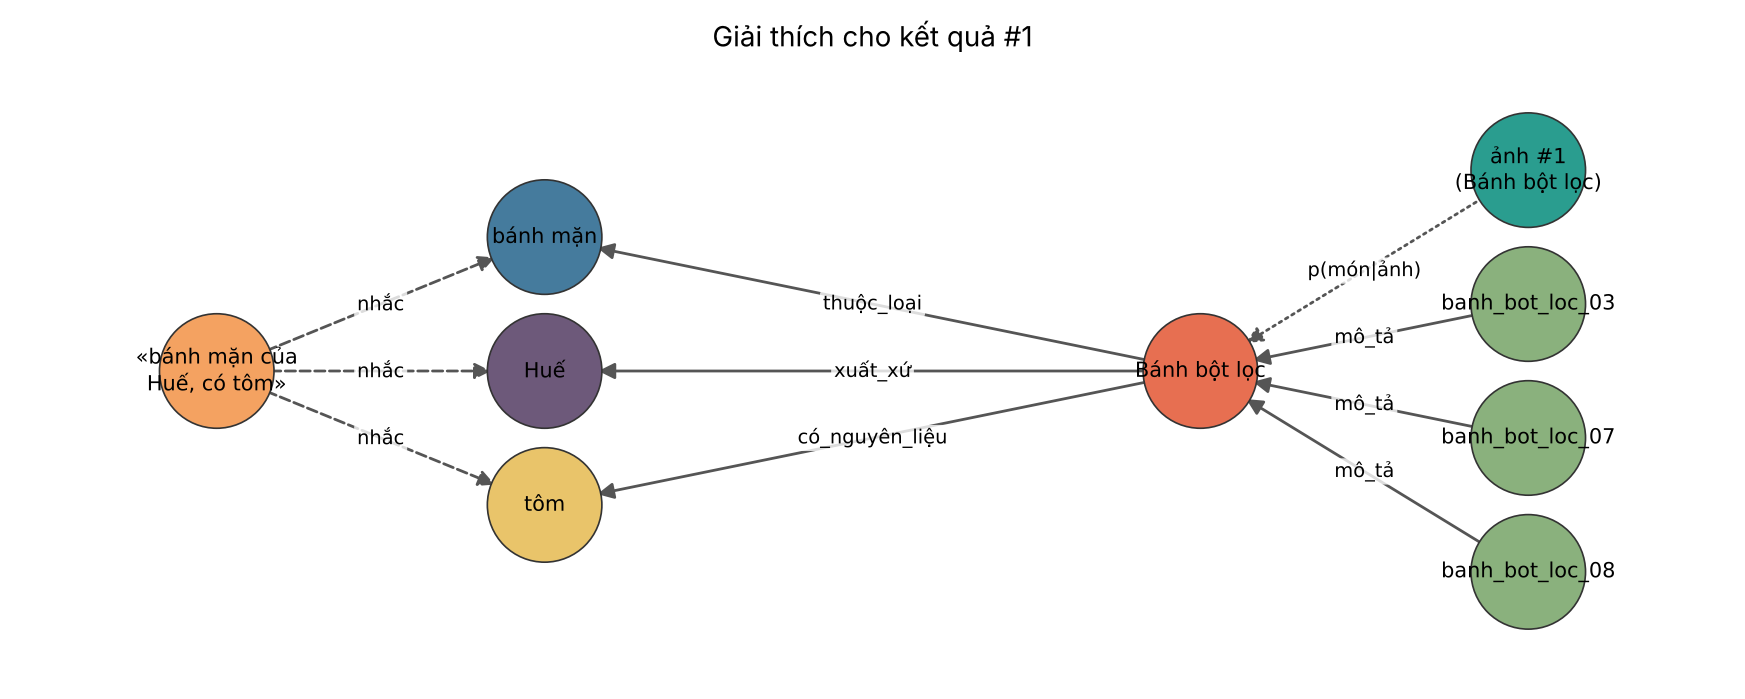

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
draw_explanation(ENG.explanation_graph(R["results"][0], R["query"]), ax, title="Giải thích cho kết quả #1")
plt.show()

### Fidelity: xoá các cạnh trong giải thích có làm điểm / thứ hạng thay đổi không?

In [5]:
import pandas as pd
rows = []
for it in R["results"][:3]:
    f = ENG.fidelity(R, it)
    rows.append(dict(hạng=it["rank"], ảnh=it["image_id"], món_d_star=ENG.name(it["d_star"]), **f))
pd.DataFrame(rows).round(3)

,hạng,ảnh,món_d_star,n_edges,score_before,rank_before,score_after_expl,rank_after_expl,score_after_rand,rank_after_rand
0,1,img_banh_bot_loc_10,Bánh bột lọc,6,5.052,1,-0.189,48,5.040,1.0
1,2,img_banh_bot_loc_06,Bánh bột lọc,6,3.914,2,-0.395,97,3.900,2.2
2,3,img_bun_oc_04,Bánh bột lọc,6,3.665,3,0.445,11,3.701,2.8


Một truy vấn **gián tiếp 2 bước** (vùng suy ra qua tỉnh) và một truy vấn **không dấu**:

In [6]:
for q in ["món sợi nước của Nam Bộ, có mắm cá", "ca phe trung"]:
    ENG.print_result(ENG.search(q, k=3)); print("-" * 100)

Truy vấn: 'món sợi nước của Nam Bộ, có mắm cá'   (gallery: test, 101 ảnh)
Thực thể nhận ra trong KG: ['món sợi nước [loại món]', 'Nam Bộ [vùng]', 'mắm cá [nguyên liệu]']
P(món | truy vấn): Bún mắm 1.00, Bánh canh cua 0.00, Hủ tiếu Nam Vang 0.00

#1 img_hu_tieu_nam_vang_03  [Hủ tiếu Nam Vang]  điểm +4.84 = CLIP +0.10 + đồ thị +4.74
   qua món «Bún mắm» ✗ (100% điểm đồ thị)
    Bún mắm —thuộc_loại→ món sợi nước
    Bún mắm —xuất_xứ→ Sóc Trăng —thuộc_vùng→ Nam Bộ
    Bún mắm —có_nguyên_liệu→ mắm cá
    ảnh bằng chứng —mô_tả→ Bún mắm : img_bun_mam_07, img_bun_mam_03, img_bun_mam_04

#2 img_banh_canh_cua_02  [Bánh canh cua]  điểm +4.67 = CLIP +0.08 + đồ thị +4.58
   qua món «Bún mắm» ✗ (100% điểm đồ thị)
    Bún mắm —thuộc_loại→ món sợi nước
    Bún mắm —xuất_xứ→ Sóc Trăng —thuộc_vùng→ Nam Bộ
    Bún mắm —có_nguyên_liệu→ mắm cá
    ảnh bằng chứng —mô_tả→ Bún mắm : img_bun_mam_03, img_bun_mam_07, img_bun_mam_04

#3 img_mi_quang_07  [Mì Quảng]  điểm +4.57 = CLIP +0.08 + đồ thị +4.49
   qua mó

## 3. Giao diện nhỏ (ipywidgets)

Nhập truy vấn, chọn top-k, gallery và có/không kiểm tra fidelity rồi bấm **Tìm**. Mỗi kết quả hiện ảnh, điểm tách CLIP / đồ thị, đường đi KG và đồ thị con giải thích.

In [7]:
import ipywidgets as W

q = W.Text(value="đồ uống của Hà Nội có trứng", description="Truy vấn", continuous_update=False, layout=W.Layout(width="60%"))
k = W.IntSlider(value=5, min=1, max=10, description="top-k")
gal = W.ToggleButtons(options=["test", "all"], description="Gallery")
fid = W.Checkbox(value=False, description="Fidelity cho top-3")
btn = W.Button(description="Tìm", button_style="primary")
examples = W.Dropdown(options=["— ví dụ —", "bánh mặn của Huế, có tôm", "món sợi nước của Nam Bộ, có mắm cá",
                               "bánh gói lá dong ngày Tết", "món kho của Nam Bộ có cá", "chả giò chiên giòn", "Phở bò"],
                      description="Ví dụ")
out = W.Output()

def on_search(_=None):
    with out:
        out.clear_output()
        R = ENG.search(q.value, k=k.value, gallery=gal.value)
        F = {it["rank"]: ENG.fidelity(R, it) for it in R["results"][:3]} if fid.value else None
        display(HTML(result_html(ENG, R, with_graph=True, fid=F)))

def on_example(ch):
    if ch["new"] != "— ví dụ —":
        q.value = ch["new"]   # đổi q.value sẽ tự gọi on_search

btn.on_click(on_search); q.observe(lambda ch: on_search(), names="value"); examples.observe(on_example, names="value")
display(W.VBox([W.HBox([q, btn]), W.HBox([k, gal, fid]), examples, out]))
on_search()

## 4. Ghi chú

- `gallery="test"`: ảnh test của seed 0, cạnh `mô_tả` của chúng **không** có trong đồ thị nên mô hình phải tự suy ảnh→món. `gallery="all"` gồm cả ảnh train (đã có cạnh `mô_tả`), chỉ để minh hoạ.
- Với B/32 trên CPU, độ chính xác ảnh→món thấp hơn mô hình H/14 của báo cáo; số liệu chính thức nằm ở `results/mmkg/`.
- Fidelity ở đây không huấn luyện lại GNN, nên là cận dưới (giống `xai_per_query.csv`).